# EOD assignment, ground-truth recording (2 fish, 1 silent)

Recording `2024-02-13T14_33_21` (`data/2_fish_silent`): two fish in the tank, one of them electrically silent, so (almost) every
recorded EOD comes from the same fish. Running the assignment here tests it: a good method should give nearly all EODs to one fish.

Steps:
1. **Files**: what is in each file.
2. **Mask quality**: per-frame metrics on the ZEUS masks; keep only frames where both masks are clearly good.
3. **Electric field per fish**: resistive (ω = 0) unit-current field of each candidate emitter (`eod_assign.candidate_field`,
   built on `compute_electric_field`), the other fish as skin + interior body, midlines from `midline_methods`.
4. **Assignment**: each EOD goes to the fish whose modelled electrode-pair pattern is closest to the recorded one
   (`eod_assign.assign_eod`'s rule).
5. **Distribution** of assigned EODs, fish 0 vs fish 1.
6. **Length scaling**: emitted current ∝ L^e for e = 0, 1, 1.5, 2, with the shape-only comparison and with one that keeps amplitude.
7. **EODs given to the silent fish**: what those frames have in common, and 20 examples (tank, masks, recorded vs model traces).

In [1]:
import os, pickle, subprocess
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.ndimage import binary_dilation
from scipy.spatial import cKDTree
import mask_metrics as mm                         # ZEUS crop unpacking + per-mask shape metrics (sets the Agg backend...)
%matplotlib inline
from compute_electric_field import mask_to_grid
from midline_methods import fish_midline_with_head
from eod_assign import (load_electrode_pairs, eod_sample_count, recorded_pair_traces, peak_pattern, rank1_pattern,
                        candidate_field, pair_voltages, compare_patterns, assign_eod)

DATA = 'data/2_fish_silent'
EOD_CSV = f'{DATA}/Data_1fish_2024-02-13T14_33_21.csv'
RAW_MAT = f'{DATA}/EODdata_2024-02-13T14_33_21.mat'
TRACK_PKL = f'{DATA}/elephantnose_20240213T143321_tracking_final.pkl'
VIDEOS = [f'{DATA}/video2024-02-13T14_33_21.avi', f'{DATA}/annotated_video-2fish1silent.mp4']
ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'

FISH = (0, 1)                                   # ZEUS labels: 0 = smaller fish (green), 1 = larger fish (pink)
FISH_COLOR = {0: '#2E8B57', 1: '#D45087'}
FS = 50000.0                                    # electrode sampling rate (Hz)

# mask quality thresholds (per fish and frame)
AREA_TOL = 0.20                                 # area within 20% of that fish's median area
LENGTH_RANGE = (0.7, 1.2)                       # principal-axis length / that fish's median
MIN_LARGEST_FRAC = 0.99                         # >= 99% of the mask in one connected piece
MAX_STEP_PX = 15                                # centroid moves <= 15 px to the previous AND next frame
MAX_DAREA = 0.15                                # area changes <= 15% to the previous AND next frame
CONTACT_GAP = 5                                 # masks closer than 5 px count as touching
KP, KP_SCORE, KP_MIN_FRAC = ('head', 'mouth', 'middle'), 0.5, 0.8   # CSV keypoints vs masks (EOD frames only)

# field model (as in eod_electrode_comparison.ipynb, with a coarser grid for speed)
N = 150                                         # tank grid resolution (N x N)
n_poles = 100                                   # n_poles + 1 point currents along each midline, tail -> head
delta_h = 0.5                                   # skin thickness, in grid-cell units
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)
N_EVENTS = 2000                                 # good EODs assigned with the forward model (None = all, ~0.5 s per fish)
SEED = 0
OUT = 'results/eod_ground_truth'                # cached model voltages, tables and example figures

## 1. The files

### 1a. EOD table (`Data_1fish_*.csv`)
One row per detected EOD: video `Frame` (0-indexed, the same index as the mask frames), `Time` (s), 5 keypoints × (x, y, score) for
2 fish from a separate keypoint tracker, and a 25-sample snippet of each of the 10 electrode pairs around the EOD.

In [2]:
df_eod = pd.read_csv(EOD_CSV)
n_samp = eod_sample_count(df_eod)
elec_cols = [c for c in df_eod.columns if c.startswith('electrode_')]
print(f"{len(df_eod)} EODs x {df_eod.shape[1]} columns ({len(elec_cols) // n_samp} electrode pairs x {n_samp} samples)")
print(f"Frame {df_eod.Frame.min()}..{df_eod.Frame.max()} | Time {df_eod.Time.min():.2f}..{df_eod.Time.max():.0f} s | "
      f"mean EOD rate {len(df_eod) / df_eod.Time.max():.1f} Hz | {df_eod.Frame.duplicated().sum()} frames hold 2 EODs")
display(df_eod.drop(columns=elec_cols).head(3))
display(df_eod[['Frame', 'Time'] + elec_cols[:4] + elec_cols[-2:]].head(3))

18770 EODs x 282 columns (10 electrode pairs x 25 samples)
Frame 1..51398 | Time 0.01..1028 s | mean EOD rate 18.3 Hz | 117 frames hold 2 EODs


,Frame,Time,chin_x_1,chin_y_1,score_chin_1,mouth_x_1,mouth_y_1,score_mouth_1,head_x_1,head_y_1,...,score_mouth_2,head_x_2,head_y_2,score_head_2,middle_x_2,middle_y_2,score_middle_2,tail_x_2,tail_y_2,score_tail_2
0,1,0.010604,28.025162,564.248352,0.562817,32.297394,579.400269,0.766807,48.279312,608.503540,...,0.620123,67.905937,712.024780,0.769653,63.652607,800.343994,0.714198,103.953026,863.488281,0.630088
1,3,0.054763,28.011362,559.751465,0.586887,32.209774,575.366760,0.769250,48.034813,608.052124,...,0.629055,67.887459,712.269653,0.752630,63.613697,800.099792,0.669656,107.548920,860.245422,0.641658
2,5,0.100322,27.733377,555.658691,0.595341,31.943581,571.465454,0.759071,47.688988,604.457092,...,0.593095,67.995621,712.268005,0.755882,63.466667,800.102905,0.652050,108.491096,856.514343,0.513416


,Frame,Time,electrode_1_time_1,electrode_1_time_2,electrode_1_time_3,electrode_1_time_4,electrode_10_time_24,electrode_10_time_25
0,1,0.010604,0.003969,0.007169,0.010525,0.015112,-0.000567,-0.000597
1,3,0.054763,0.005222,0.008944,0.012763,0.019371,-0.000737,-0.000147
2,5,0.100322,0.006040,0.010277,0.014938,0.022554,-0.000398,-0.000264


### 1b. Raw electrode recording (`EODdata_*.mat`, MATLAB v7.3 / HDF5)
`NewRaw`: 10 channels at 50 kHz for the whole session, NaN outside the stored EOD snippets. `Synctime`: times (s) of the video sync
pulses. The CSV snippets are cut from `NewRaw` (CSV pair 1 = channel 1). Only the first 0.3 s is loaded here.

NewRaw: shape (51400000, 10), float64
Synctime: shape (133, 1), float64
NewRaw: 10 channels at 50 kHz, 81% NaN in this window
Synctime: 133 sync pulses, first [ 6.83 12.34 22.   31.5 ] s, every ~7.7 s


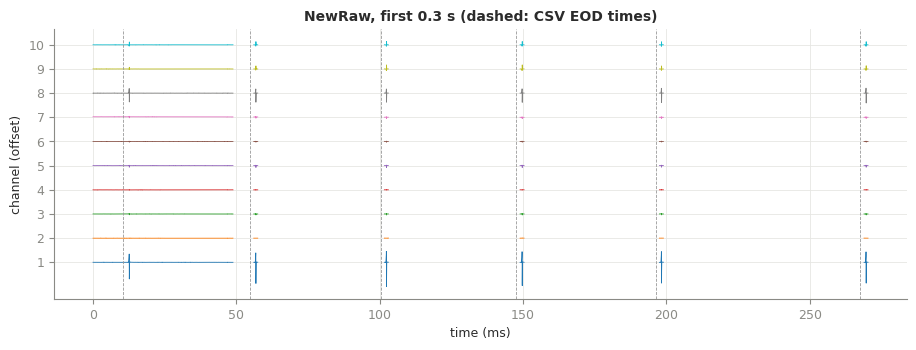

In [3]:
with h5py.File(RAW_MAT, 'r') as f:
    for k in f: print(f"{k}: shape {f[k].shape}, {f[k].dtype}")
    sync = f['Synctime'][:, 0]
    raw = f['NewRaw'][:int(0.3 * FS)]
print(f"NewRaw: {raw.shape[1]} channels at {FS / 1e3:.0f} kHz, {np.isnan(raw[:, 0]).mean():.0%} NaN in this window")
print(f"Synctime: {len(sync)} sync pulses, first {np.round(sync[:4], 2)} s, every ~{np.median(np.diff(sync)):.1f} s")

t = np.arange(len(raw)) / FS
fig, ax = plt.subplots(figsize=(11, 3.5))
for ch in range(raw.shape[1]):
    ax.plot(t * 1e3, raw[:, ch] / np.nanmax(np.abs(raw)) + ch, lw=0.6)
for tt in df_eod.Time[df_eod.Time < t[-1]]:
    ax.axvline(tt * 1e3, color='0.6', lw=0.6, ls='--')
ax.set(xlabel='time (ms)', ylabel='channel (offset)', yticks=range(10), yticklabels=range(1, 11),
       title='NewRaw, first 0.3 s (dashed: CSV EOD times)')
plt.show()

### 1c. ZEUS masks (`*_tracking_final.pkl`)
One record per video frame (all 51,447 frames): fish labels, bounding boxes `(y0, y1, x0, x1)`, bit-packed mask crops and areas.
Labels 0 and 1 are the two fish; 2–5 would be non-fish remnants.

In [4]:
with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
frames, fps, P = trk['frames'], trk['fps'], trk['shape'][0]
n_frames = len(frames)
print(trk['readme'][:250], '...')
print(f"keys: {list(trk)}\nlabels: {trk['labels_key']}\ncolours: {trk['colour_key']}")
print("masks per frame:", pd.Series([len(fr['labels']) for fr in frames.values()]).value_counts().to_dict())
fr = frames[1000]
display(pd.DataFrame({'label': fr['labels'], 'box (y0, y1, x0, x1)': fr['boxes'], 'area': fr['areas'],
                      'obj_id': fr['obj_ids'], 'packed mask bytes': [len(m) for m in fr['masks']]}))

def frame_crops(k):
    '''{fish label: (box (y0, y1, x0, x1), bool crop)} of one tracked frame, remnant labels dropped.'''
    fr = frames[k]
    return {l: (b, mm.unpack_crop(p, b)) for l, p, b in zip(fr['labels'], fr['masks'], fr['boxes']) if l in FISH}

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask).'''
    m = np.zeros((len(FISH), P, P), bool)
    for l, ((y0, y1, x0, x1), c) in frame_crops(k).items():
        m[l, y0:y1, x0:x1] = c
    return m

ZEUS 2-fish identity tracking, recording two_fish_20240213T143321 (video2024-02-13T14_33_21.avi, all 51,447 frames, 912x912, 50 fps; frame k of the pickle is frame k of the AVI): 51447 frames at 50.0 fps, 912x912 px.

d["frames"][k] for frame k (0-ba ...
keys: ['readme', 'video', 'fps', 'shape', 'labels_key', 'colour_key', 'label_remap_run_to_canonical', 'frames', 'provenance']
labels: {1: 'largest fish', 0: 'smallest fish', 2: 'not a fish (remnant)', 3: 'not a fish (remnant)', 4: 'not a fish (remnant)', 5: 'not a fish (remnant)'}
colours: {1: 'pink', 0: 'green'}
masks per frame: {2: 51125, 1: 322}


,label,"box (y0, y1, x0, x1)",area,obj_id,packed mask bytes
0,1,"(117, 361, 25, 66)",3800,0,1251
1,0,"(382, 565, 32, 79)",3013,1,1076


### 1d. Electrodes and videos
Electrode pixel coordinates `(x, y)` with polarity, one row per recording pair. The raw video (`.avi`) has the same frames as the
masks; `annotated_video-2fish1silent.mp4` is the annotated copy. One frame is shown with the masks, CSV keypoints and electrodes.

,pair,x1,y1,pol1,x2,y2,pol2
0,1,88,880,-,456,873,+
1,2,494,873,+,838,866,-
2,3,887,797,-,881,461,+


video2024-02-13T14_33_21.avi: codec, width, height, fps, frames = mpeg4,912,912,50/1,51447
annotated_video-2fish1silent.mp4: codec, width, height, fps, frames = h264,1192,1280,30/1,18420


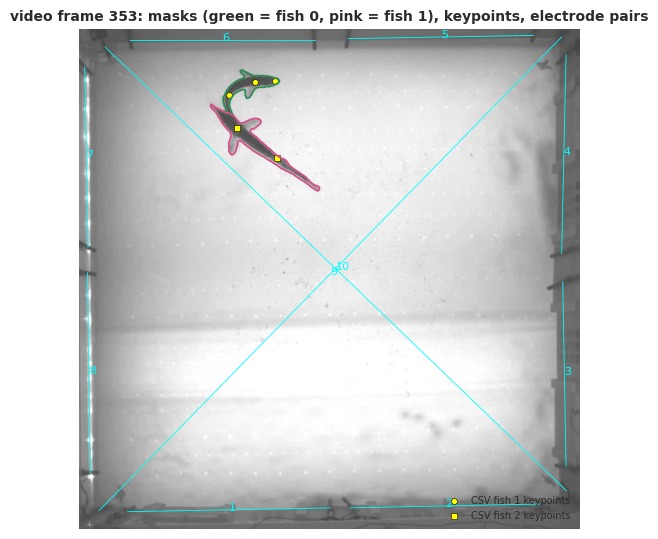

In [5]:
df_el = pd.read_csv(ELECTRODES_CSV)
display(df_el.head(3))
pairs = load_electrode_pairs(ELECTRODES_CSV, P)          # [(pair id, + point, - point)] in tank coords (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]

for v in VIDEOS:
    info = subprocess.run(['ffprobe', '-v', 'error', '-select_streams', 'v:0', '-show_entries',
                           'stream=codec_name,width,height,r_frame_rate,nb_frames', '-of', 'csv=p=0', v],
                          capture_output=True, text=True).stdout.strip()
    print(f"{v.split('/')[-1]}: codec, width, height, fps, frames = {info}")

def video_frame(k, path=VIDEOS[0]):
    '''Grayscale (P, P) frame k of the raw video (needs ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / fps:.4f}', '-i', path, '-frames:v', '1',
                          '-f', 'rawvideo', '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

row = df_eod.iloc[200]; k = int(row.Frame)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(video_frame(k), cmap='gray')
for l, m in enumerate(frame_masks(k)):
    if m.any(): ax.contour(m, levels=[0.5], colors=[FISH_COLOR[l]], linewidths=1.2)
for i, mk in ((1, 'o'), (2, 's')):
    ax.scatter([row[f'{p}_x_{i}'] for p in KP], [row[f'{p}_y_{i}'] for p in KP], marker=mk, s=18, c='yellow', ec='k', lw=0.4,
               label=f'CSV fish {i} keypoints')
for _, r in df_el.iterrows():
    ax.plot([r.x1, r.x2], [r.y1, r.y2], color='cyan', lw=0.6)
    ax.text((r.x1 + r.x2) / 2, (r.y1 + r.y2) / 2, int(r.pair), color='cyan', fontsize=8)
ax.legend(fontsize=7, loc='lower right'); ax.set_axis_off()
ax.set_title(f'video frame {k}: masks (green = fish 0, pink = fish 1), keypoints, electrode pairs')
plt.show()

## 2. Mask quality

Per fish and frame (all frames), a mask passes when:

| check | why |
|---|---|
| exactly one mask with that label, no remnant masks in the frame | no duplicated or spurious detections |
| area within 20% of the fish's median area | catches merged, cut or partial masks |
| principal-axis length within 0.7–1.2 × the fish's median | catches odd shapes (strongly curled bodies give poor midlines) |
| ≥ 99% of the pixels in one connected piece | catches fragmented masks |
| centroid moves ≤ 15 px and area changes ≤ 15% to both neighbouring frames | catches identity swaps and one-frame glitches |
| more than 5 px from the other fish's mask | touching fish give ambiguous boundaries and head sides |

A frame is **good** when both fish pass every check. EOD frames are then also checked against the independent CSV keypoints: ≥ 80% of
the confident (score > 0.5) head/mouth/middle points must lie on a mask, and each mask must hold at least one (the CSV fish numbering
does not follow the mask labels, so a point may lie on either mask).

In [6]:
def in_contact(a, b, gap=CONTACT_GAP):
    '''True if two (box, crop) masks come within `gap` px (8-neighbour steps) of each other.'''
    (ba, ca), (bb, cb) = a, b
    if max(ba[0] - bb[1], bb[0] - ba[1], ba[2] - bb[3], bb[2] - ba[3]) > gap: return False   # boxes far apart
    y0, x0 = min(ba[0], bb[0]) - gap, min(ba[2], bb[2]) - gap
    win = np.zeros((2, max(ba[1], bb[1]) + gap - y0, max(ba[3], bb[3]) + gap - x0), bool)
    for w, ((r0, r1, c0, c1), c) in zip(win, (a, b)): w[r0 - y0:r1 - y0, c0 - x0:c1 - x0] = c
    return bool((binary_dilation(win[0], np.ones((3, 3)), iterations=gap) & win[1]).any())

rows = []
for k in range(n_frames):
    labels, crops = frames[k]['labels'], frame_crops(k)
    contact = in_contact(*crops.values()) if len(crops) == 2 else False
    for l, (box, crop) in crops.items():
        rows.append(dict(frame=k, fish=l, n_masks=labels.count(l), n_remnant=sum(x not in FISH for x in labels),
                         contact=contact, **mm.shape_metrics(crop, box)))
q = pd.DataFrame(rows)

for f in FISH:                                  # temporal stability, worst of the previous and next frame
    s = q[q.fish == f].set_index('frame').reindex(range(n_frames))
    step = np.hypot(s.cx.diff(), s.cy.diff())
    darea = (s.px / s.px.shift(1) - 1).abs()
    q.loc[q.fish == f, 'step'] = np.fmax(step, step.shift(-1)).fillna(np.inf).loc[q.frame[q.fish == f]].to_numpy()
    q.loc[q.fish == f, 'darea'] = np.fmax(darea, darea.shift(-1)).fillna(np.inf).loc[q.frame[q.fish == f]].to_numpy()
med = q.groupby('fish')[['px', 'major']].transform('median')
q['area_ratio'], q['length_ratio'] = q.px / med.px, q.major / med.major
q.head()

,frame,fish,n_masks,n_remnant,contact,cy,cx,major,minor,orient,n_comp,largest_frac,px,step,darea,area_ratio,length_ratio
0,0,1,1,0,True,738.348412,76.617430,231.190579,79.387612,94.750266,1,1.0,5416,0.475767,0.001108,1.184602,1.037132
1,0,0,1,0,True,612.339322,55.487680,100.772729,30.633391,53.233323,1,1.0,1948,0.935082,0.009240,0.756946,0.618370
2,1,1,1,0,True,738.386573,77.091664,232.143273,80.836685,94.019078,1,1.0,5422,2.057467,0.007193,1.185914,1.041406
3,1,0,1,0,True,611.446083,55.211089,103.679809,30.820587,54.801937,1,1.0,1966,1.460610,0.026958,0.763940,0.636209
4,2,1,1,0,True,740.442876,77.160877,235.990662,81.628032,92.602933,1,1.0,5383,2.057467,0.008174,1.177384,1.058666


fish,fish 0: % frames passing,fish 1: % frames passing
"one mask, no remnants",100.0,100.0
area within 20% of median,94.4,96.6
length 0.7-1.2 x median,95.6,98.4
>= 99% in one piece,97.9,98.6
step <= 15 px,96.4,98.4
area change <= 15%,97.9,99.2
not touching other fish,88.7,88.8
all,78.2,84.4


good frames (both fish pass every check): 38391 / 51447 (75%)


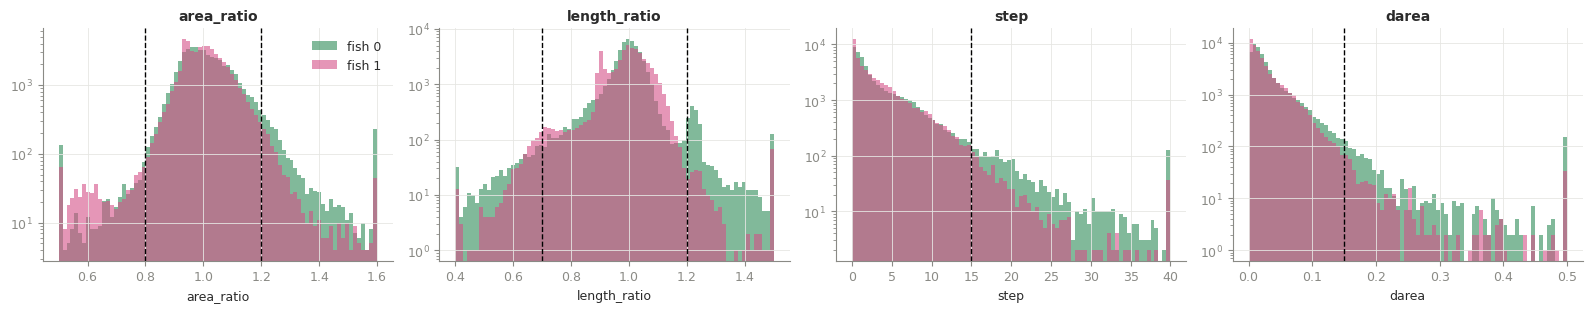

In [7]:
checks = pd.DataFrame({
    'one mask, no remnants': (q.n_masks == 1) & (q.n_remnant == 0),
    f'area within {AREA_TOL:.0%} of median': (q.area_ratio - 1).abs() <= AREA_TOL,
    f'length {LENGTH_RANGE[0]}-{LENGTH_RANGE[1]} x median': q.length_ratio.between(*LENGTH_RANGE),
    f'>= {MIN_LARGEST_FRAC:.0%} in one piece': q.largest_frac >= MIN_LARGEST_FRAC,
    f'step <= {MAX_STEP_PX} px': q.step <= MAX_STEP_PX,
    f'area change <= {MAX_DAREA:.0%}': q.darea <= MAX_DAREA,
    'not touching other fish': ~q.contact,
})
checks['all'] = checks.all(axis=1)
display((checks.groupby(q.fish).mean().T * 100).round(1).rename(columns=lambda f: f'fish {f}: % frames passing'))

per_frame = checks['all'].groupby(q.frame).agg(['all', 'size'])
good_frames = per_frame.index[per_frame['all'] & (per_frame['size'] == len(FISH))]
print(f"good frames (both fish pass every check): {len(good_frames)} / {n_frames} ({len(good_frames) / n_frames:.0%})")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, col, lim, thr in zip(ax, ['area_ratio', 'length_ratio', 'step', 'darea'],
                            [(0.5, 1.6), (0.4, 1.5), (0, 40), (0, 0.5)],
                            [(1 - AREA_TOL, 1 + AREA_TOL), LENGTH_RANGE, (MAX_STEP_PX,), (MAX_DAREA,)]):
    for f in FISH:
        a.hist(q.loc[q.fish == f, col].clip(*lim), bins=80, range=lim, alpha=0.6, color=FISH_COLOR[f], label=f'fish {f}')
    for t in thr: a.axvline(t, color='k', ls='--', lw=1)
    a.set(xlabel=col, yscale='log', title=col)
ax[0].legend(); plt.tight_layout(); plt.show()

In [8]:
def kp_agreement(row, crops):
    '''Fraction of the confident CSV head/mouth/middle keypoints (both CSV fish) lying on a mask, and whether every mask holds one.'''
    hit, n, n_in = dict.fromkeys(crops, False), 0, 0
    for i in (1, 2):
        for p in KP:
            if not row[f'score_{p}_{i}'] > KP_SCORE: continue
            n += 1; x, y = int(round(row[f'{p}_x_{i}'])), int(round(row[f'{p}_y_{i}']))
            for l, ((y0, y1, x0, x1), c) in crops.items():
                if y0 <= y < y1 and x0 <= x < x1 and c[y - y0, x - x0]:
                    hit[l] = True; n_in += 1; break
    return (n_in / n if n else np.nan), all(hit.values())

cand = df_eod[df_eod.Frame.isin(good_frames)]
kp = pd.DataFrame([kp_agreement(r, frame_crops(int(r.Frame))) for _, r in cand.iterrows()],
                  index=cand.index, columns=['kp_frac', 'kp_both'])
good_eods = cand[(kp.kp_frac >= KP_MIN_FRAC) & kp.kp_both]
print(f"EODs: {len(df_eod)} total | {len(cand)} in good mask frames | {len(good_eods)} also agree with the CSV keypoints "
      f"({len(good_eods) / len(df_eod):.0%} kept)")
print(f"keypoints on a mask, over the good-frame EODs: median {kp.kp_frac.median():.0%}")

EODs: 18770 total | 12121 in good mask frames | 12026 also agree with the CSV keypoints (64% kept)
keypoints on a mask, over the good-frame EODs: median 100%


## 3. Electric field of each candidate fish (one example EOD)

For one good EOD, each fish in turn emits unit current along its midline (`multipole_sources`: tail sink, equal sources along the
body), its own body transparent and the other fish a skin + interior body. Head side by the area rule (`fish_midline_with_head`),
which holds outside contacts, and good frames have none. Left: potential φ and E = −∇φ of each candidate. Right: the recorded
pair voltages at the peak sample vs each candidate's model, both scaled to max |v| = 1, with the L2 distance `assign_eod` uses.

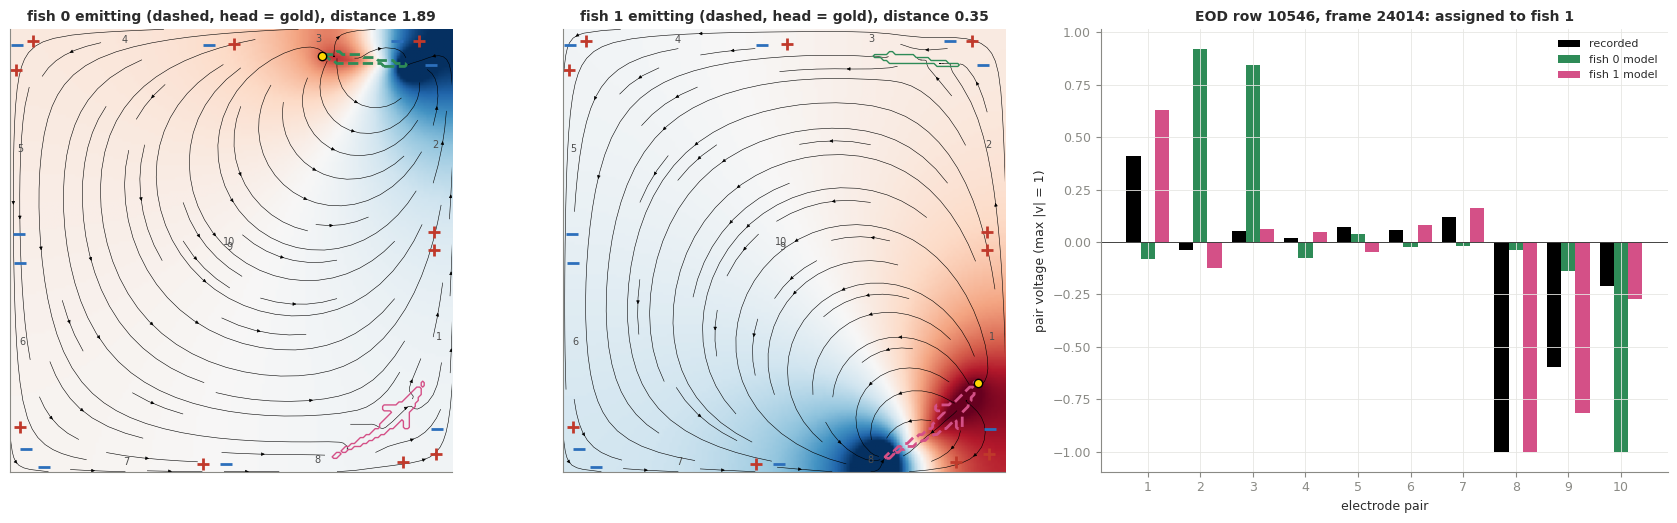

In [9]:
def frame_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords, tail -> head, of every fish in a (n_fish, P, P) mask stack.'''
    return [fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] for m in fm]

row = good_eods.iloc[len(good_eods) // 2]; k = int(row.Frame)
fm, mids = frame_masks(k), frame_midlines(frame_masks(k))
a = assign_eod(row, fm, mids, pairs, N, delta_h, MAT, n_samp)

g, h = np.linspace(0, 1, N), 1.0 / (N - 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.3), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
for f in FISH:
    phi = candidate_field(fm, f, mids[f], N, delta_h, MAT).real
    Ex, Ey = (-d for d in np.gradient(phi, h))
    v = np.percentile(np.abs(phi), 99)
    ax[f].imshow(phi.T, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-v, vmax=v)
    ax[f].streamplot(g, g, Ex.T, Ey.T, color='k', density=0.8, linewidth=0.4, arrowsize=0.5)
    for l in FISH:
        ax[f].contour(g, g, mask_to_grid(fm[l], N).T.astype(float), levels=[0.5], colors=[FISH_COLOR[l]],
                      linewidths=2 if l == f else 1, linestyles='--' if l == f else '-')
    ax[f].plot(*mids[f][-1], 'o', color='gold', mec='k', ms=6)                   # head
    for pid, pp, pm in pairs:
        ax[f].plot(*pp, '+', color='#C0392B', ms=8, mew=2); ax[f].plot(*pm, '_', color='#2C6FBB', ms=8, mew=2)
        ax[f].text(*(0.5 * (pp + pm)), str(pid), fontsize=7, color='0.3')
    ax[f].set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xticks=[], yticks=[],
              title=f'fish {f} emitting (dashed, head = gold), distance {a["distances"][f]:.2f}')
x, w = np.arange(len(pair_ids)), 0.27
ax[2].bar(x - w, a['v_rec'], w, color='k', label='recorded')
for j, f in enumerate(FISH):
    ax[2].bar(x + j * w, a['v_sim'][f], w, color=FISH_COLOR[f], label=f'fish {f} model')
ax[2].axhline(0, color='k', lw=0.5)
ax[2].set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='pair voltage (max |v| = 1)',
          title=f'EOD row {row.name}, frame {k}: assigned to fish {a["fish"]}')
ax[2].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Assigning the good EODs (model-pattern match)

For every sampled EOD, each fish's unit-current field in that frame is solved (2 solves per EOD) and sampled at the electrodes,
the same steps `assign_eod` runs internally. The raw model voltages are kept, so section 6 can rescale them without solving again.
The EOD goes to the fish whose peak-normalized pattern is closest to the recording, which is `assign_eod`'s rule; the first few EODs
are checked against `assign_eod` itself. Run on `N_EVENTS` random good EODs (set `N_EVENTS = None` for all).

In [10]:
rng = np.random.default_rng(SEED)
ev = good_eods if N_EVENTS is None or N_EVENTS >= len(good_eods) else \
     good_eods.loc[np.sort(rng.choice(good_eods.index, N_EVENTS, replace=False))]

CACHE = f'{OUT}/model_voltages_N{N}_{len(ev)}eods_seed{SEED}.pkl'     # raw model voltages: reruns skip the field solves
if os.path.exists(CACHE) and (res := pd.read_pickle(CACHE)).index.equals(ev.index):
    print(f'model voltages loaded from {CACHE}')
else:
    out = []
    for n, (i, row) in enumerate(ev.iterrows()):
        fm = frame_masks(int(row.Frame)); mids = frame_midlines(fm)
        v_rec, _ = peak_pattern(recorded_pair_traces(row, pair_ids, n_samp))
        u = [pair_voltages(candidate_field(fm, f, mids[f], N, delta_h, MAT).real, pairs, N) for f in FISH]   # unit current
        out.append(dict(row=i, frame=int(row.Frame), time=row.Time, v_rec=v_rec, u=np.array(u),
                        L=np.array([np.linalg.norm(np.diff(m, axis=0), axis=1).sum() for m in mids])))
        if (n + 1) % 100 == 0: print(f"{n + 1}/{len(ev)} EODs")
    res = pd.DataFrame(out).set_index('row')
    os.makedirs(OUT, exist_ok=True); res.to_pickle(CACHE)
R, U = np.stack(res.v_rec), np.stack(res.u)            # recorded (n, n_pairs), unit-current model (n, n_fish, n_pairs)

def shape_assign(M):
    '''assign_eod's rule on model voltages M (n, n_fish, n_pairs): L2 distance of the peak-normalized patterns, minimized over
       the model's sign; the smallest distance wins. Returns (fish (n,), distances (n, n_fish)).'''
    D = np.array([[compare_patterns(m, r)[0] for m in Ms] for Ms, r in zip(M, R)])
    return D.argmin(axis=1), D

res['fish'], D = shape_assign(U)
res['d0'], res['d1'] = D[:, 0], D[:, 1]
for i in res.index[:3]:                                # same answer as assign_eod itself
    row = df_eod.loc[i]; fm = frame_masks(int(row.Frame))
    assert assign_eod(row, fm, frame_midlines(fm), pairs, N, delta_h, MAT, n_samp)['fish'] == res.fish[i]
res[['frame', 'time', 'fish', 'd0', 'd1']].head()

100/2000 EODs


200/2000 EODs


300/2000 EODs


400/2000 EODs


500/2000 EODs


600/2000 EODs


... (11 outputs left out)

1800/2000 EODs


1900/2000 EODs


2000/2000 EODs


,frame,time,fish,d0,d1
row,,,,,
27,60,1.193404,1,1.388856,0.148579
28,61,1.216424,1,1.472204,0.126273
30,63,1.258903,1,1.557163,0.118931
34,67,1.343782,1,1.808182,0.115487
51,95,1.899313,1,1.629109,0.780435


## 5. Distribution of assigned EODs

fish 0: 102 EODs (5.1%) | fish 1: 1898 EODs (94.9%)


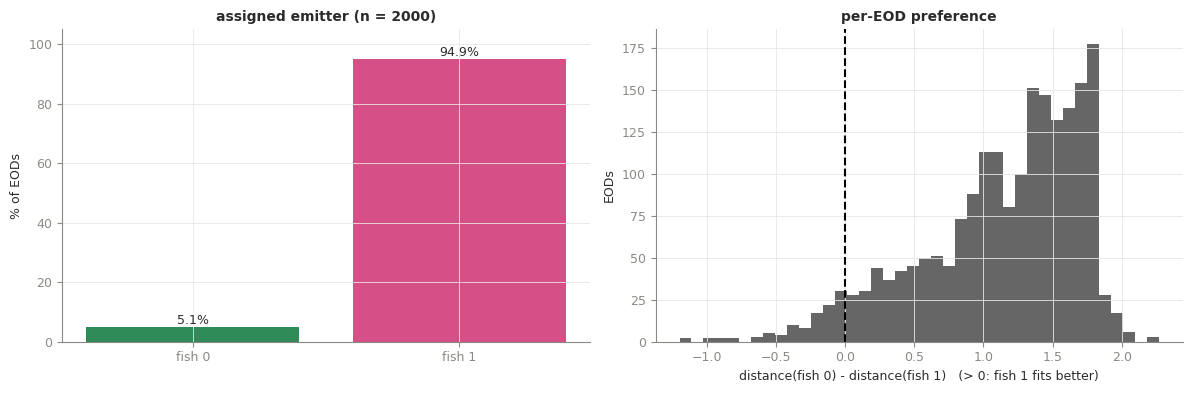

In [11]:
c = res.fish.value_counts().reindex(FISH, fill_value=0)
print(' | '.join(f"fish {f}: {c[f]} EODs ({c[f] / len(res):.1%})" for f in FISH))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar([f'fish {f}' for f in FISH], 100 * c / len(res), color=[FISH_COLOR[f] for f in FISH])
ax[0].bar_label(ax[0].containers[0], fmt='%.1f%%')
ax[0].set(ylabel='% of EODs', ylim=(0, 105), title=f'assigned emitter (n = {len(res)})')
ax[1].hist(res.d0 - res.d1, bins=40, color='0.4')
ax[1].axvline(0, color='k', ls='--')
ax[1].set(xlabel='distance(fish 0) - distance(fish 1)   (> 0: fish 1 fits better)', ylabel='EODs',
          title='per-EOD preference')
plt.tight_layout(); plt.show()

## 6. Scaling the emitted current with body length

`multipole_sources` can scale the emitted current as $A = I_0 L^{e}$. The field is linear in the current, so fish $f$'s model voltages
become $L_f^{e}\,v_f$ with $v_f$ the unit-current voltages from section 4 (no new solves). $L_f$ is each fish's body length: the median
midline arc length over the sampled frames, in tank units. Only the ratio $(L_1/L_0)^e$ matters; the absolute scale is absorbed below.

Three comparisons:
- **Shape only** (`assign_eod`, sections 4–5): each pattern is scaled to max |v| = 1 before comparing, so a per-fish factor
  $L_f^{e}$ cancels exactly. Every exponent must give the same assignment; the table checks this.
- **Amplitude kept**: residual $\min_{s=\pm1}\lVert r - s\,g\,L_f^{e} v_f\rVert^2$ on the raw recorded voltages $r$, smaller residual
  wins, so a model fish also has to match the recorded amplitude. $g$ (model units → recorded volts) is one number for all
  electrodes, EODs and fish, **calibrated on fish 1 where its identity is certain**: for each of the 20 electrodes, the `N_CAL` good
  EODs in which fish 1's body (nearest mask pixel) is closest to that electrode. For each of these EODs fish 1's field is solved and
  $g_i = |r_i\cdot m_i| / \lVert m_i\rVert^2$ is the least-squares gain over the 10 pairs (sign free), with $m_i = L_1^{e} v_{i,1}$;
  $g$ is the mean of the $g_i$. Calibration EODs are kept out of the assessed sample. (Fish 0 is silent here, so an EOD with fish 1
  next to an electrode is fish 1's; with two emitting fish, the calibration EODs would also need the other fish far away.)
- **Joint max = 1**: per EOD, both fish's model vectors are divided by the largest |v| over *both* fish, so the louder fish peaks at 1
  and the quieter one stays below 1; the recording is scaled to max |v| = 1; L2 distance, sign free per fish, smallest wins. The
  relative loudness of the two fish ($\propto L_f^{e}$) is kept within each EOD, with no gain fitted across EODs.

body length (tank units): fish 0 0.193, fish 1 0.272 | ratio L1/L0 = 1.41


calibration: 200 EODs (178 distinct), fish 1 within 27.3 px of the electrode (median 12.1 px) | g at e = 0: mean 0.502, median 0.449, CV across EODs 44%


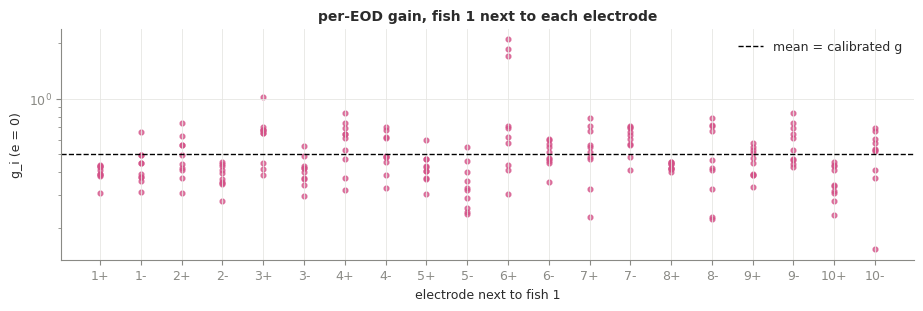

,"% fish 1, shape only","% fish 1, amplitude kept","% fish 1, joint max = 1",calibrated g,median relative residual,amplitude kept = shape-only,joint max = 1 = shape-only
exponent e,,,,,,,
0.0,94.9,95.55,96.30,0.502,0.355,95%,96%
1.0,94.9,94.30,95.30,1.850,0.357,95%,96%
1.5,94.9,94.25,94.85,3.551,0.356,95%,97%
2.0,94.9,93.90,94.35,6.815,0.357,95%,97%


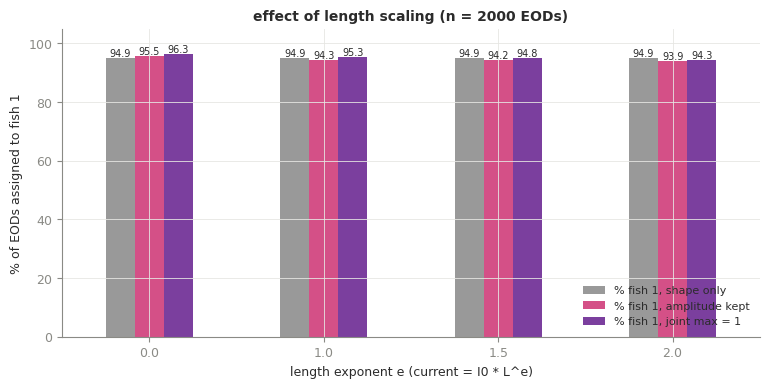

In [12]:
EXPONENTS = (0, 1, 1.5, 2)
L_fish = np.median(np.stack(res.L), axis=0)
print('body length (tank units): ' + ', '.join(f'fish {f} {L_fish[f]:.3f}' for f in FISH) +
      f' | ratio L1/L0 = {L_fish[1] / L_fish[0]:.2f}')

N_CAL, CAL_FISH = 10, 1
elec = np.array([p * (P - 1) for _, pp, pm in pairs for p in (pp, pm)])          # 20 electrodes, (row, col) px
elec_name = [f'{pid}{sign}' for pid, _, _ in pairs for sign in '+-']

def fish_to_electrodes(k, f=CAL_FISH):
    '''Distance (px) from the nearest pixel of fish f's mask in frame k to each electrode.'''
    (y0, y1, x0, x1), c = frame_crops(k)[f]
    pix = np.argwhere(c) + (y0, x0)
    return np.sqrt(((pix[:, None, :] - elec[None]) ** 2).sum(-1)).min(axis=0)

cal_pool = good_eods.drop(index=res.index)                                       # not among the assessed EODs
dist = pd.DataFrame([fish_to_electrodes(int(k)) for k in cal_pool.Frame], index=cal_pool.index, columns=elec_name)
cal = []
for el in elec_name:
    for i in dist[el].nsmallest(N_CAL).index:
        row = df_eod.loc[i]; fm = frame_masks(int(row.Frame))
        r, _ = peak_pattern(recorded_pair_traces(row, pair_ids, n_samp))
        u = pair_voltages(candidate_field(fm, CAL_FISH, frame_midlines(fm)[CAL_FISH], N, delta_h, MAT).real, pairs, N)
        cal.append(dict(row=i, electrode=el, dist_px=dist.loc[i, el], g_unit=abs(r @ u) / (u @ u)))   # g_i at e = 0
cal = pd.DataFrame(cal)
print(f"calibration: {len(cal)} EODs ({cal.row.nunique()} distinct), fish 1 within {cal.dist_px.max():.1f} px of the electrode "
      f"(median {cal.dist_px.median():.1f} px) | g at e = 0: mean {cal.g_unit.mean():.3g}, median {cal.g_unit.median():.3g}, "
      f"CV across EODs {cal.g_unit.std() / cal.g_unit.mean():.0%}")

fig, ax = plt.subplots(figsize=(11, 3))
ax.scatter(cal.electrode, cal.g_unit, s=12, color='#D45087', alpha=0.7)
ax.axhline(cal.g_unit.mean(), color='k', ls='--', lw=1, label='mean = calibrated g')
ax.set(xlabel='electrode next to fish 1', ylabel='g_i (e = 0)', yscale='log', title='per-EOD gain, fish 1 next to each electrode')
ax.legend(); plt.show()

def amplitude_assign(M, g):
    '''Amplitude-kept rule on model voltages M (n, n_fish, n_pairs) with a fixed gain g: residual ||r - s g m_f||^2 with the best
       sign s per EOD and fish; smaller residual wins. Returns (fish (n,), residuals (n, n_fish)).'''
    rr, mm2, rm = (R ** 2).sum(-1)[:, None], (M ** 2).sum(-1), np.abs(np.einsum('nk,nfk->nf', R, M))
    E = rr + g ** 2 * mm2 - 2 * g * rm
    return E.argmin(axis=1), E

def joint_assign(M):
    '''Joint max = 1 rule on model voltages M (n, n_fish, n_pairs): both fish divided by the largest |v| over both fish of that EOD,
       the recording by its own max; L2 distance minimized over each fish's sign; smallest wins. Returns (fish (n,), distances).'''
    Mn = M / np.abs(M).max(axis=(1, 2), keepdims=True)
    Rn = (R / np.abs(R).max(axis=1, keepdims=True))[:, None]
    D = np.minimum(np.linalg.norm(Rn - Mn, axis=-1), np.linalg.norm(Rn + Mn, axis=-1))
    return D.argmin(axis=1), D

scan, assigned = [], {}
for e in EXPONENTS:
    M = U * (L_fish ** e)[None, :, None]
    f_shape, _ = shape_assign(M)
    g = cal.g_unit.mean() / L_fish[CAL_FISH] ** e              # m = L_1^e v_1, so every g_i scales by L_1^-e
    f_amp, E = amplitude_assign(M, g)
    f_joint, _ = joint_assign(M)
    assigned[e] = f_joint
    scan.append({'exponent e': e, '% fish 1, shape only': 100 * (f_shape == 1).mean(),
                 '% fish 1, amplitude kept': 100 * (f_amp == 1).mean(), '% fish 1, joint max = 1': 100 * (f_joint == 1).mean(),
                 'calibrated g': g,
                 'median relative residual': np.median(np.sqrt(E.min(1) / (R ** 2).sum(1))),
                 'amplitude kept = shape-only': f'{(f_amp == f_shape).mean():.0%}',
                 'joint max = 1 = shape-only': f'{(f_joint == f_shape).mean():.0%}'})
scan = pd.DataFrame(scan).set_index('exponent e')
display(scan.round(3))

ax = scan[['% fish 1, shape only', '% fish 1, amplitude kept', '% fish 1, joint max = 1']].plot.bar(
    figsize=(9, 4), rot=0, color=['0.6', '#D45087', '#7B3F9E'])
for cont in ax.containers: ax.bar_label(cont, fmt='%.1f', fontsize=7)
ax.set(ylabel='% of EODs assigned to fish 1', ylim=(0, 105), xlabel='length exponent e (current = I0 * L^e)',
       title=f'effect of length scaling (n = {len(res)} EODs)')
ax.legend(loc='lower right', fontsize=8); plt.show()

## 7. EODs given to the silent fish

Fish 0 is silent, so every EOD that goes to fish 0 is a mistake. All three rules at e = 0 (no length scaling) are used: shape only
(section 4), amplitude kept with the calibrated gain $g$, and joint max = 1 (section 6). An EOD counts as a miss when at least one
rule gives it to fish 0.

Per EOD (misses and the rest):
- **fish gap**: smallest distance between the two masks (px).
- **distance of each fish to its nearest electrode** (px).
- **recorded |r|**: norm of the recorded pair voltages at the peak sample.
- **model similarity**: $|\cos(u_0, u_1)|$ of the two fish's unit-current patterns. Near 1, the electrodes cannot tell the fish apart.
- **fish 1 relative residual**: $\sqrt{E_1}/\lVert r\rVert$ of the amplitude-kept fit with fish 1 as emitter.
- **margin**: $(E_0 - E_1)/\lVert r\rVert^2$; negative means fish 0 fits better (amplitude kept).

In [ ]:
g0 = cal.g_unit.mean()                                          # calibrated gain at e = 0
f_amp, E = amplitude_assign(U, g0)
f_joint, Dj = joint_assign(U)
rules = pd.DataFrame({'shape only': res.fish.to_numpy(), 'amplitude kept': f_amp, 'joint max = 1': f_joint}, index=res.index)
n0 = (rules == 0).sum(axis=1)
print('EODs given to the silent fish 0 (e = 0): ' + ', '.join(f'{r} {(rules[r] == 0).sum()}' for r in rules) +
      f' | by at least one rule {(n0 > 0).sum()} ({(n0 > 0).mean():.1%}), by all three {(n0 == 3).sum()}')

def gap_px(k):
    '''Smallest distance (px) between the two fish masks of frame k.'''
    pts = [np.argwhere(c) + (b[0], b[2]) for b, c in (frame_crops(k)[f] for f in FISH)]
    return cKDTree(pts[0]).query(pts[1])[0].min()

rn = np.linalg.norm(R, axis=1)
feat = pd.DataFrame({
    'frame': res.frame, 'time': res.time, 'n rules -> fish 0': n0,
    'rules -> fish 0': [', '.join(r for r in rules if rules.at[i, r] == 0) for i in res.index],
    'fish gap (px)': [gap_px(k) for k in res.frame],
    **{f'fish {f} to nearest electrode (px)': [fish_to_electrodes(k, f).min() for k in res.frame] for f in FISH},
    'recorded |r|': rn,
    'model similarity |cos(u0, u1)|': np.abs((U[:, 0] * U[:, 1]).sum(1)) / np.linalg.norm(U, axis=2).prod(1),
    'fish 1 relative residual': np.sqrt(E[:, 1]) / rn,
    'margin (E0 - E1) / |r|^2': (E[:, 0] - E[:, 1]) / rn ** 2,
}, index=res.index)
miss = feat[n0 > 0]
os.makedirs(OUT, exist_ok=True); miss.to_csv(f'{OUT}/eods_to_silent_fish.csv')

num = feat.columns[4:]
group = np.where(n0 > 0, 'to fish 0 (>= 1 rule)', 'to fish 1 (all rules)')
display(feat[num].groupby(group).median().T.round(3).rename_axis('median'))
display(miss.sort_values('margin (E0 - E1) / |r|^2').round(3))

In [ ]:
cen = q.set_index(['frame', 'fish'])[['cx', 'cy']]
hit = feat[n0 == 0]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, col in zip(ax.flat, num):
    lo, hi = np.percentile(feat[col], [0.5, 99.5])
    for d, c, lab in ((hit, '0.5', f'to fish 1 (n = {len(hit)})'), (miss, '#2E8B57', f'to fish 0 (n = {len(miss)})')):
        a.hist(d[col].clip(lo, hi), bins=30, range=(lo, hi), density=True, histtype='step', lw=1.8, color=c, label=lab)
    a.set(xlabel=col, yticks=[])
ax[0, 0].legend(fontsize=8)
a = ax[1, 3]                                                    # where the fish are when a miss happens
c1 = cen.loc[[(k, 1) for k in hit.frame]]
a.scatter(c1.cx, c1.cy, s=3, color='0.75', label='fish 1, EODs to fish 1')
for k in miss.frame:
    (x0, y0), (x1, y1) = cen.loc[(k, 0)], cen.loc[(k, 1)]
    a.plot([x0, x1], [y0, y1], color='0.4', lw=0.4)
a.scatter(*cen.loc[[(k, 0) for k in miss.frame]].T.to_numpy(), s=10, color=FISH_COLOR[0], label='fish 0, misses')
a.scatter(*cen.loc[[(k, 1) for k in miss.frame]].T.to_numpy(), s=10, color=FISH_COLOR[1], label='fish 1, misses')
a.scatter(elec[:, 1], elec[:, 0], marker='x', color='k', s=15, label='electrodes')
a.set(xlim=(0, P), ylim=(P, 0), aspect='equal', xticks=[], yticks=[], title='mask centroids')
a.legend(fontsize=6, loc='lower right')
plt.tight_layout(); plt.show()

bins = pd.cut(feat.time, 20)
rate = (n0 > 0).groupby(bins, observed=False).mean() * 100
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.bar([b.mid for b in rate.index], rate, width=0.9 * (rate.index[0].length), color='#2E8B57')
ax.set(xlabel='Time', ylabel='% to fish 0', title='misses over the recording (20 time bins)'); plt.show()

### 20 examples

Random misses (seed `SEED`), in time order. Left: video frame with both masks (green = fish 0, silent; pink = fish 1), midlines with
the head (gold) and the electrode pairs (+ red, − blue). Right: one panel per electrode pair, same y scale, with three traces:
- **recorded** (black);
- **fish 0 model** (green, dashed) and **fish 1 model** (pink).

The model is resistive, so it predicts one voltage per pair, $s_f\,g\,u_f$ (amplitude kept, e = 0, calibrated $g$, best sign $s_f$).
It is drawn as that voltage times the recording's own EOD waveform (the rank-1 waveform of the 10 recorded traces, scaled to 1 at the
peak sample, grey line), so model and recording agree in time and can be compared pair by pair. Figures are also saved in `OUT`.

In [ ]:
N_EXAMPLES = 20
t_ms = np.arange(n_samp) / FS * 1e3
ex = miss.sample(min(N_EXAMPLES, len(miss)), random_state=SEED).sort_values('time')
os.makedirs(f'{OUT}/fish0_examples', exist_ok=True)
for i in ex.index:
    j, k, row = res.index.get_loc(i), int(res.frame[i]), df_eod.loc[i]
    V = recorded_pair_traces(row, pair_ids, n_samp)
    r, ts = peak_pattern(V)
    w = rank1_pattern(V)[1]; w = w / w[ts]                      # EOD waveform, 1 at the peak sample
    model = {f: np.sign(r @ U[j, f]) * g0 * U[j, f][:, None] * w for f in FISH}

    fig = plt.figure(figsize=(19, 6.4))
    gs = fig.add_gridspec(2, 6, width_ratios=[2.3, 1, 1, 1, 1, 1], wspace=0.08, hspace=0.3)
    a = fig.add_subplot(gs[:, 0])
    a.imshow(video_frame(k), cmap='gray')
    fm = frame_masks(k); over = np.zeros((P, P, 4))
    for f, m in zip(FISH, frame_midlines(fm)):
        over[fm[f]] = to_rgba(FISH_COLOR[f], 0.45)
        a.contour(fm[f], levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1)
        m = m * (P - 1)
        a.plot(m[:, 1], m[:, 0], color=FISH_COLOR[f], lw=1); a.plot(m[-1, 1], m[-1, 0], 'o', color='gold', mec='k', ms=5)
    a.imshow(over)
    for pid, pp, pm in pairs:
        (yp, xp), (ym, xm) = pp * (P - 1), pm * (P - 1)
        a.plot([xp, xm], [yp, ym], color='cyan', lw=0.5)
        a.plot(xp, yp, '+', color='#E74C3C', ms=8, mew=2); a.plot(xm, ym, '_', color='#3498DB', ms=8, mew=2)
        a.text((xp + xm) / 2, (yp + ym) / 2, str(pid), color='cyan', fontsize=9)
    a.set_axis_off()
    a.set_title(f"frame {k}: fish gap {feat.at[i, 'fish gap (px)']:.0f} px, nearest electrode "
                f"fish 0 {feat.at[i, 'fish 0 to nearest electrode (px)']:.0f} px / fish 1 {feat.at[i, 'fish 1 to nearest electrode (px)']:.0f} px",
                fontsize=9)

    lim = 1.1 * max(np.abs(V).max(), *(np.abs(m).max() for m in model.values()))
    for p, pid in enumerate(pair_ids):
        a = fig.add_subplot(gs[p // 5, 1 + p % 5])
        a.axhline(0, color='0.85', lw=0.6); a.axvline(t_ms[ts], color='0.85', lw=0.8)
        a.plot(t_ms, V[p], color='k', lw=2, label='recorded')
        for f in FISH:
            a.plot(t_ms, model[f][p], color=FISH_COLOR[f], lw=1.5, ls='--' if f == 0 else '-', label=f'fish {f} model')
        a.set_ylim(-lim, lim); a.set_title(f'pair {pid}', fontsize=9)
        if p % 5: a.set_yticklabels([])
        if p < 5: a.set_xticklabels([])
        if p == 5: a.set(xlabel='ms', ylabel='recorded units')
        if p == 0: a.legend(fontsize=7, loc='lower left')
    fig.suptitle(f"EOD row {i}, t = {row.Time:.2f} | to fish 0 by: {feat.at[i, 'rules -> fish 0']} | "
                 f"amplitude-kept relative residual fish 0 {np.sqrt(E[j, 0]) / rn[j]:.2f}, fish 1 {np.sqrt(E[j, 1]) / rn[j]:.2f} | "
                 f"shape distance fish 0 {D[j, 0]:.2f}, fish 1 {D[j, 1]:.2f}", fontsize=10)
    fig.savefig(f'{OUT}/fish0_examples/eod{i}_frame{k}.png', dpi=110, bbox_inches='tight')
    plt.show()